## Copyright Information

In [ ]:
##Copyright Information

# Copyright 2020 MIT 6.S191 Introduction to Deep Learning. All Rights Reserved.
# 
# Licensed under the MIT License. You may not use this file except in compliance
# with the License. Use and/or modification of this code outside of 6.S191 must
# reference:
#
# © MIT 6.S191: Introduction to Deep Learning
# http://introtodeeplearning.com
#

##Laboratory 3: Reinforcement Learning
Reinforcement learning (RL) is a subset of machine learning which poses learning problems as interactions between agents and environments. It often assumes agents have no prior knowledge of a world, so they must learn to navigate environments by optimizing a reward function. Within an environment, an agent can take certain actions and receive feedback, in the form of positive or negative rewards, with respect to their decision. As such, an agent's feedback loop is somewhat akin to the idea of "trial and error", or the manner in which a child might learn to distinguish between "good" and "bad" actions.

In practical terms, our RL agent will interact with the environment by taking an action at each timestep, receiving a corresponding reward, and updating its state according to what it has "learned".

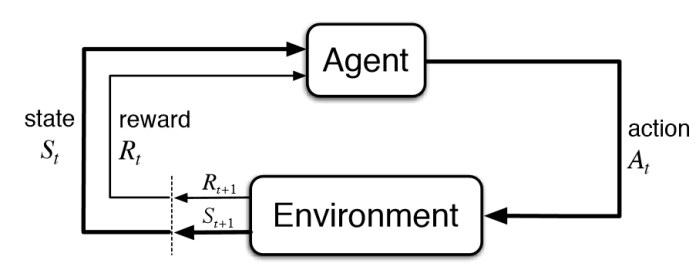

While the ultimate goal of reinforcement learning is to teach agents to act in the real, physical world, games provide a convenient proving ground for developing RL algorithms and agents. Games have some properties that make them particularly well suited for RL:

In many cases, games have perfectly describable environments. For example, all rules of chess can be formally written and programmed into a chess game simulator;
Games are massively parallelizable. Since they do not require running in the real world, simultaneous environments can be run on large data clusters;
Simpler scenarios in games enable fast prototyping. This speeds up the development of algorithms that could eventually run in the real-world; and
... Games are fun!
In previous labs, we have explored both supervised (with LSTMs, CNNs) and unsupervised / semi-supervised (with VAEs) learning tasks. Reinforcement learning is fundamentally different, in that we are training a deep learning algorithm to govern the actions of our RL agent, that is trying, within its environment, to find the optimal way to achieve a goal. The goal of training an RL agent is to determine the best next step to take to earn the greatest final payoff or return. In this lab, we focus on building a reinforcement learning algorithm to master two different environments with varying complexity.

Cartpole: Balance a pole, protruding from a cart, in an upright position by only moving the base left or right. Environment with a low-dimensional observation space.
Pong: Beat your competitors (whether other AI or humans!) at the game of Pong. Environment with a high-dimensional observation space -- learning directly from raw pixels.
Let's get started! First we'll import TensorFlow, the course package, and some dependencies.

In [21]:
!apt-get install -y xvfb python-opengl x11-utils > /dev/null 2>&1
!pip install gym pyvirtualdisplay scikit-video > /dev/null 2>&1

import tensorflow as tf

import numpy as np
import base64, io, time, gym
import IPython, functools
import matplotlib.pyplot as plt
from tqdm import tqdm

!pip install mitdeeplearning
import mitdeeplearning as mdl

Looking in indexes: https://pypi.org/simple, https://us-python.pkg.dev/colab-wheels/public/simple/


Before we dive in, let's take a step back and outline our approach, which is generally applicable to reinforcement learning problems in general:

**Initialize our environment and our agent**: here we will describe the different observations and actions the agent can make in the environemnt.

**Define our agent's memory**: this will enable the agent to remember its past actions, observations, and rewards.

**Define a reward function**: describes the reward associated with an action or sequence of actions.

**Define the learning algorithm**: this will be used to reinforce the agent's good behaviors and discourage bad behaviors.


#Part 1: Cartpole
##3.1 Define the Cartpole environment and agent
###Environment
In order to model the environment for both the Cartpole and Pong tasks, we'll be using a toolkit developed by OpenAI called OpenAI Gym. It provides several pre-defined environments for training and testing reinforcement learning agents, including those for classic physics control tasks, Atari video games, and robotic simulations. To access the Cartpole environment, we can use env = gym.make("CartPole-v0"), which we gained access to when we imported the gym package. We can instantiate different environments by passing the enivronment name to the make function.

One issue we might experience when developing RL algorithms is that many aspects of the learning process are inherently random: initializing game states, changes in the environment, and the agent's actions. As such, it can be helpful to set a initial "seed" for the environment to ensure some level of reproducibility. Much like you might use numpy.random.seed, we can call the comparable function in gym, seed, with our defined environment to ensure the environment's random variables are initialized the same each time.

In [23]:
### Instantiate the Cartpole environment ###

env = gym.make("CartPole-v0")
env.seed(1)

/usr/local/lib/python3.8/dist-packages/gym/envs/registration.py:593: UserWarning: WARN: The environment CartPole-v0 is out of date. You should consider upgrading to version `v1`.
  logger.warn(
/usr/local/lib/python3.8/dist-packages/gym/core.py:317: DeprecationWarning: WARN: Initializing wrapper in old step API which returns one bool instead of two. It is recommended to set `new_step_api=True` to use new step API. This will be the default behaviour in future.
  deprecation(
/usr/local/lib/python3.8/dist-packages/gym/wrappers/step_api_compatibility.py:39: DeprecationWarning: WARN: Initializing environment in old step API which returns one bool instead of two. It is recommended to set `new_step_api=True` to use new step API. This will be the default behaviour in future.
  deprecation(
/usr/local/lib/python3.8/dist-packages/gym/core.py:256: DeprecationWarning: WARN: Function `env.seed(seed)` is marked as deprecated and will be removed in the future. Please use `env.reset(seed=seed)` inste

[1]

In Cartpole, a pole is attached by an un-actuated joint to a cart, which moves along a frictionless track. The pole starts upright, and the goal is to prevent it from falling over. The system is controlled by applying a force of +1 or -1 to the cart. A reward of +1 is provided for every timestep that the pole remains upright. The episode ends when the pole is more than 15 degrees from vertical, or the cart moves more than 2.4 units from the center of the track. A visual summary of the cartpole environment is depicted below:

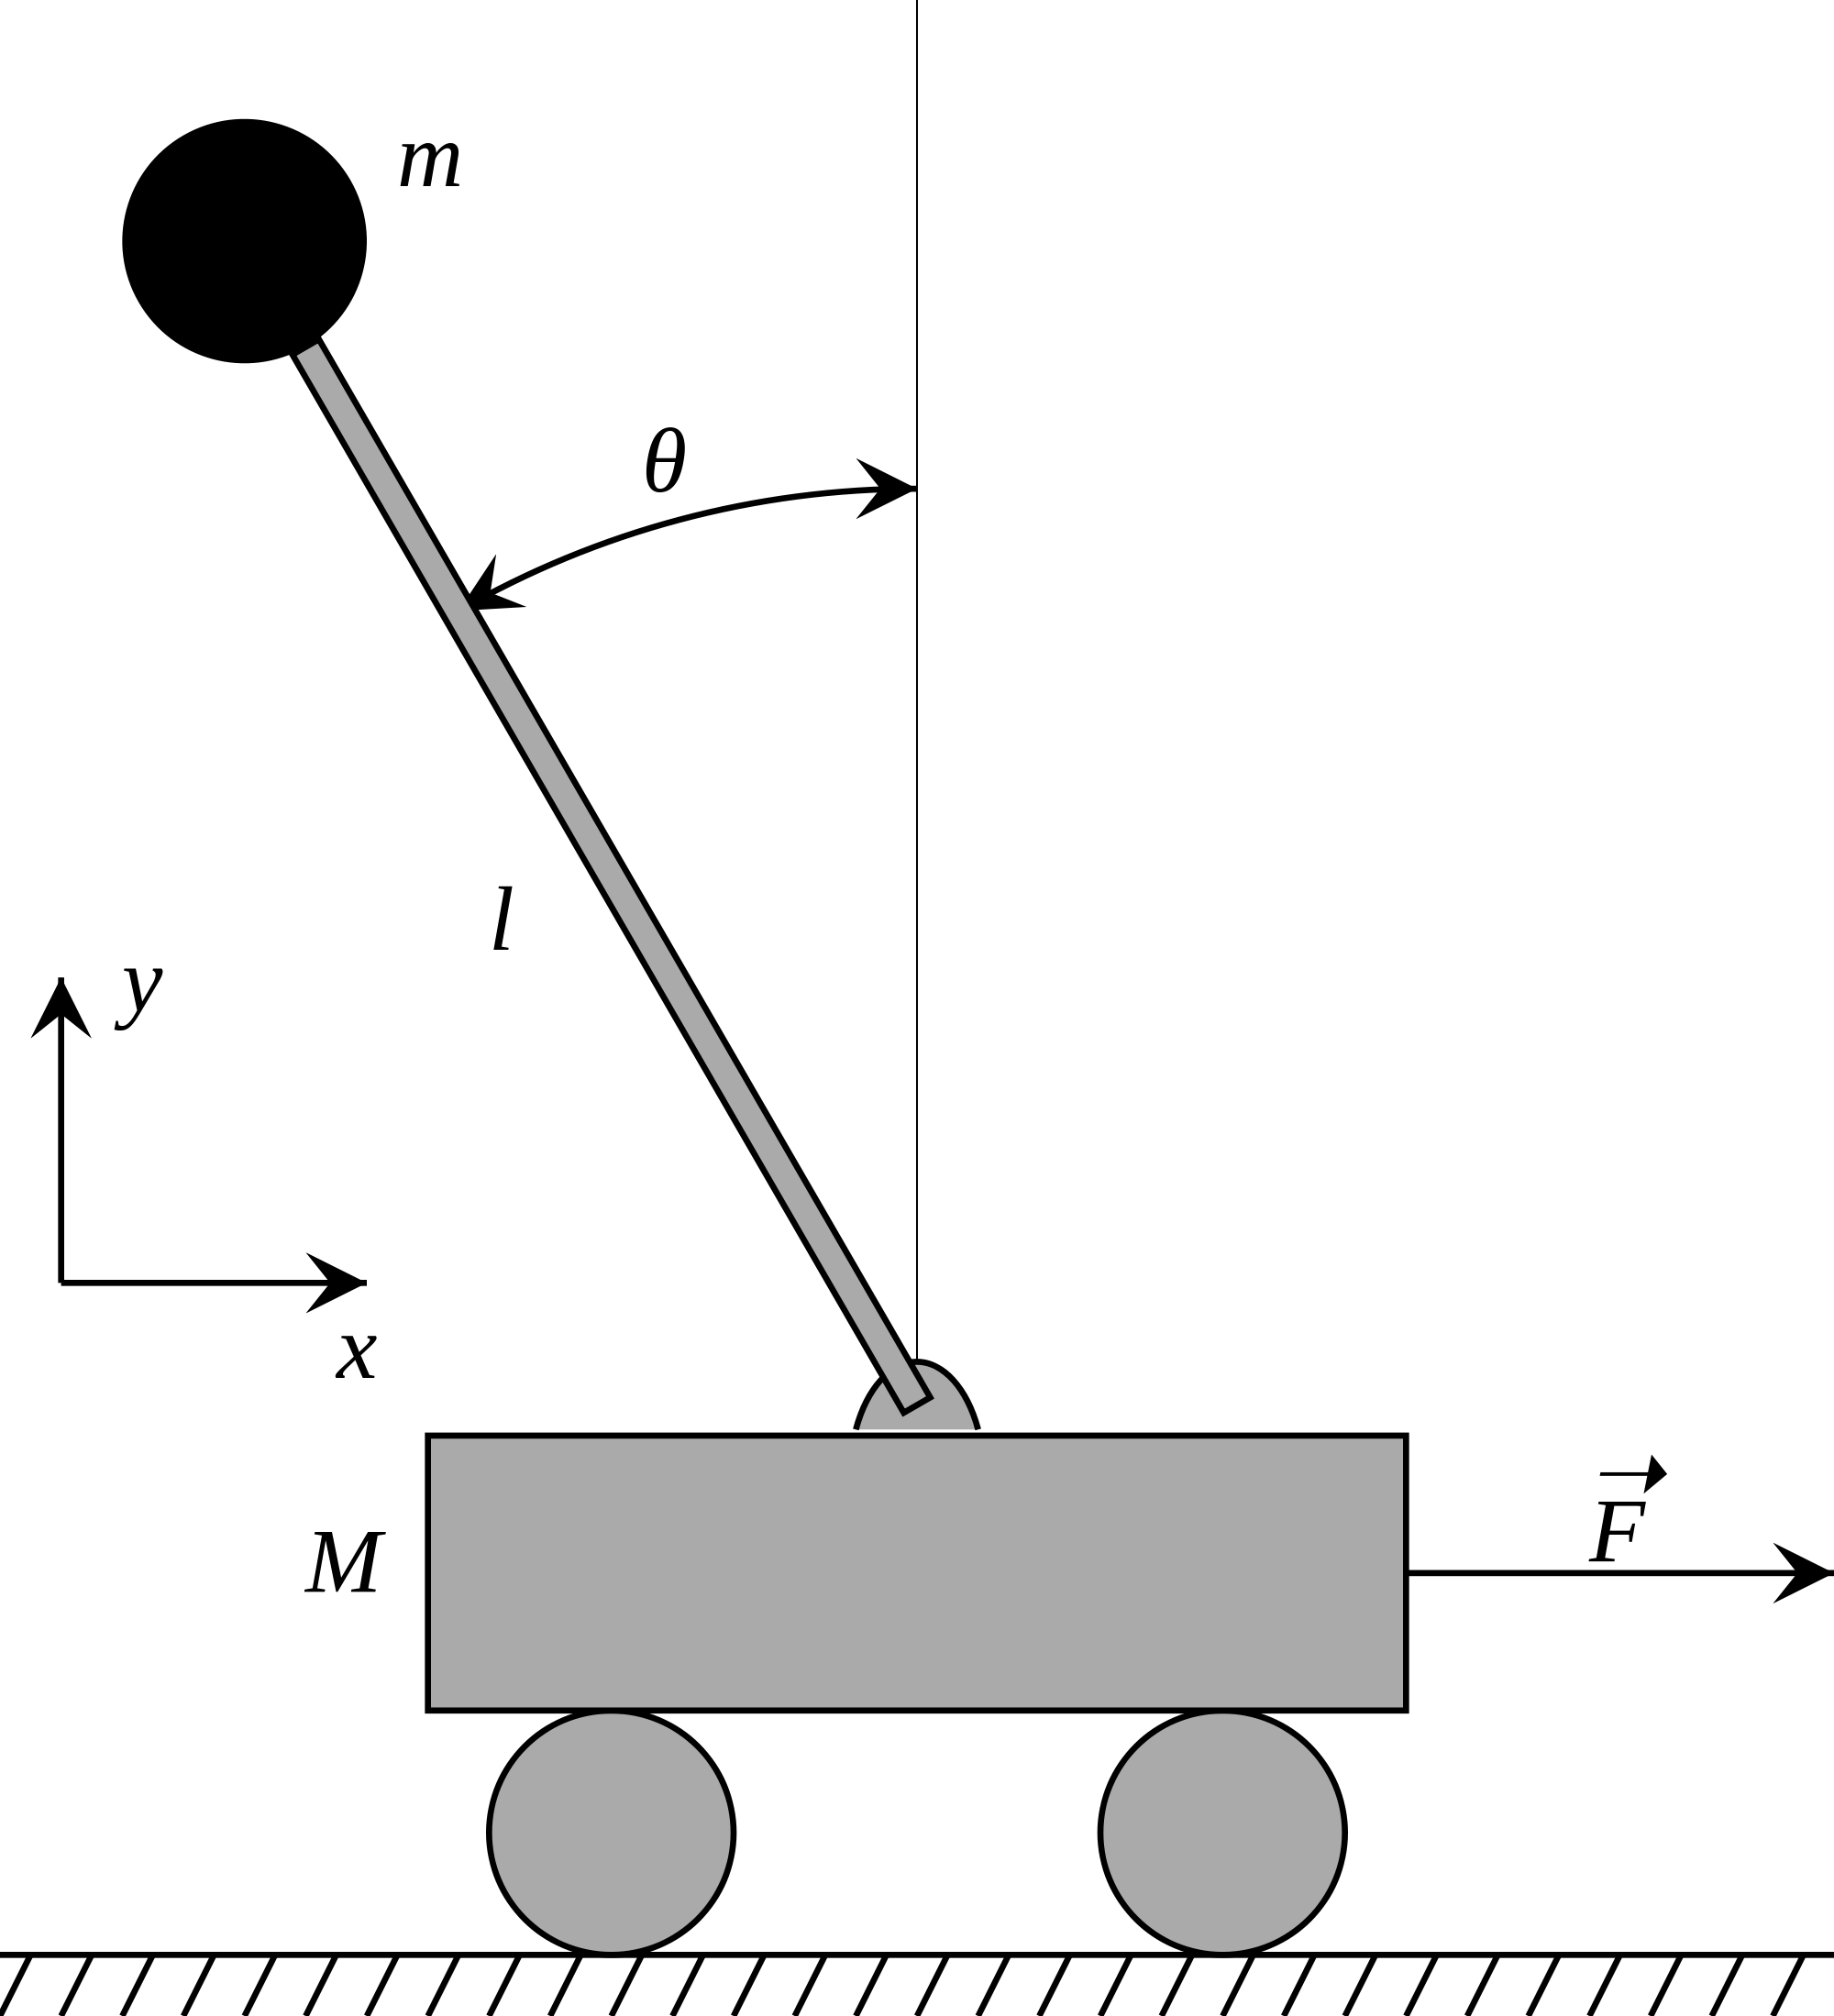

Given this setup for the environment and the objective of the game, we can think about: 1) what observations help define the environment's state; 2) what actions the agent can take.

First, let's consider the observation space. In this Cartpole environment our observations are:

1. Cart position
2. Cart velocity
3. Pole angle
Pole rotation rate

We can confirm the size of the space by querying the environment's observation space:

In [24]:
n_observations = env.observation_space
print("Environment has observation space =", n_observations)

Environment has observation space = Box([-4.8000002e+00 -3.4028235e+38 -4.1887903e-01 -3.4028235e+38], [4.8000002e+00 3.4028235e+38 4.1887903e-01 3.4028235e+38], (4,), float32)


Environment has observation space = Box(4,)

Second, we consider the action space. At every time step, the agent can move either right or left. Again we can confirm the size of the action space by querying the environment:

In [25]:
n_actions = env.action_space.n
print("Number of possible actions that the agent can choose from =", n_actions)

Number of possible actions that the agent can choose from = 2


#Cartpole agent

Now that we have instantiated the environment and understood the dimensionality of the observation and action spaces, we are ready to define our agent. In deep reinforcement learning, a deep neural network defines the agent. This network will take as input an observation of the environment and output the probability of taking each of the possible actions. Since Cartpole is defined by a low-dimensional observation space, a simple feed-forward neural network should work well for our agent. We will define this using the Sequential API.

In [36]:
### Define the Cartpole agent ###

# Defines a feed-forward neural network
def create_cartpole_model():
  model = tf.keras.models.Sequential([
      # First Dense layer
      tf.keras.layers.Dense(units=32, activation='relu'),

      # TODO: Define the last Dense layer, which will provide the network's output.
      # Think about the space the agent needs to act in!
      tf.keras.layers.Dense(units=n_actions, activation=None),
  ])
  return model

cartpole_model = create_cartpole_model()

Now that we have defined the core network architecture, we will define an action function that executes a forward pass through the network, given a set of observations, and samples from the output. This sampling from the output probabilities will be used to select the next action for the agent.

**Critically, this action function is totally general -- we will use this function for both Cartpole and Pong, and it is applicable to other RL tasks, as well!**

In [27]:
### Define the agent's action function ###

# Function that takes observations as input, executes a forward pass through model, 
# and outputs a sampled action.
# Arguments:
# model: the network that defines our agent
# observation: observation which is fed as input to the model
# Returns:
# action: choice of agent action
def choose_action(model, observation):
  # add batch dimension to the observation
  observation = np.expand_dims(observation, axis=0)

  #'''TODO: feed the observations through the model to predict the log probabilities of each possible action.'''
  logits = model.predict(observation) # Ref: RohitLearner - GitHub
  
  # pass the log probabilities through a softmax to compute true probabilities
  prob_weights = tf.nn.softmax(logits).numpy()
  
  #'''TODO: randomly sample from the prob_weights to pick an action.
  #Hint: carefully consider the dimensionality of the input probabilities (vector) and the output action (scalar)'''
  action = np.random.choice(n_actions, size=1, p=prob_weights.flatten())[0] # Ref: RohitLearner - GitHub

  return action

#3.2 Define the agent's memory
Now that we have instantiated the environment and defined the agent network architecture and action function, we are ready to move on to the next step in our RL workflow:

1. **Initialize our environment and our agent**: here we will describe the different observations and actions the agent can make in the environemnt.

3. **Define our agent's memory**: this will enable the agent to remember its past actions, observations, and rewards.

2. **Define the learning algorithm**: this will be used to reinforce the agent's good behaviors and discourage bad behaviors.

In reinforcement learning, training occurs alongside the agent's acting in the environment; an episode refers to a sequence of actions that ends in some terminal state, such as the pole falling down or the cart crashing. The agent will need to remember all of its observations and actions, such that once an episode ends, it can learn to "reinforce" the good actions and punish the undesirable actions via training. Our first step is to define a simple memory buffer that contains the agent's observations, actions, and received rewards from a given episode.

**Once again, note the modularity of this memory buffer -- it can and will be applied to other RL tasks as well!**

In [28]:
### Agent Memory ###

class Memory:
  def __init__(self): 
      self.clear()

  # Resets/restarts the memory buffer
  def clear(self): 
      self.observations = []
      self.actions = []
      self.rewards = []

  # Add observations, actions, rewards to memory
  def add_to_memory(self, new_observation, new_action, new_reward): 
      self.observations.append(new_observation)
      #'''TODO: update the list of actions with new action'''
      self.actions.append(new_action) # Ref: RohitLearner - GitHub
      #'''TODO: update the list of rewards with new reward'''
      self.rewards.append(new_reward) # Ref: RohitLearner - GitHub
      # TODO: your update code here
        
memory = Memory()

# 3.3 Reward function
We're almost ready to begin the learning algorithm for our agent! The next step is to compute the rewards of our agent as it acts in the environment. Since we (and the agent) is uncertain about if and when the game or task will end (i.e., when the pole will fall), it is useful to emphasize getting rewards now rather than later in the future -- this is the idea of discounting. This is a similar concept to discounting money in the case of interest. Recall from lecture, we use reward discount to give more preference at getting rewards now rather than later in the future. The idea of discounting rewards is similar to discounting money in the case of interest.

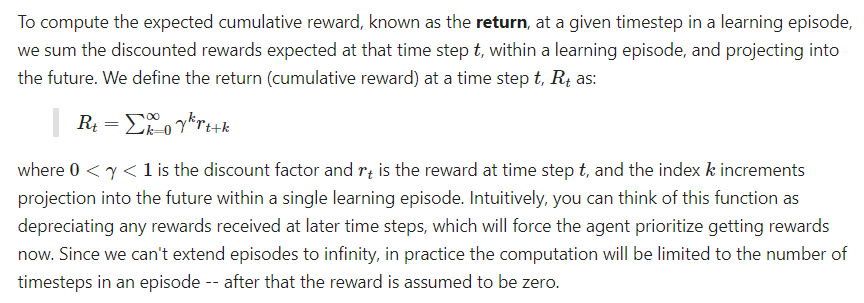

Take note of the form of this sum -- we'll have to be clever about how we implement this function. Specifically, we'll need to initialize an array of zeros, with length of the number of time steps, and fill it with the real discounted reward values as we loop through the rewards from the episode, which will have been saved in the agents memory. What we ultimately care about is which actions are better relative to other actions taken in that episode -- so, we'll normalize our computed rewards, using the mean and standard deviation of the rewards across the learning episode.

In [29]:
### Reward function ###

# Helper function that normalizes an np.array x
def normalize(x):
  x -= np.mean(x)
  x /= np.std(x)
  return x.astype(np.float32)

# Compute normalized, discounted, cumulative rewards (i.e., return)
# Arguments:
# rewards: reward at timesteps in episode
# gamma: discounting factor
# Returns:
# normalized discounted reward
def discount_rewards(rewards, gamma=0.95): 
  discounted_rewards = np.zeros_like(rewards)
  R = 0
  for t in reversed(range(0, len(rewards))):
      # update the total discounted reward
      R = R * gamma + rewards[t]
      discounted_rewards[t] = R
      
  return normalize(discounted_rewards)

#3.4 Learning algorithm
Now we can start to define the learing algorithm which will be used to reinforce good behaviors of the agent and discourage bad behaviours. In this lab, we will focus on policy gradient methods which aim to **maximize** the likelihood of actions that result in large rewards. Equivalently, this means that we want to **minimize** the negative likelihood of these same actions. We achieve this by simply **scaling** the probabilities by their associated rewards -- effectively amplifying the likelihood of actions that result in large rewards.

Since the log function is monotonically increasing, this means that minimizing **negative likelihood** is equivalent to minimizing negative log-likelihood. Recall that we can easily compute the **negative log-likelihood** of a discrete action by evaluting its softmax cross entropy. Like in supervised learning, we can use stochastic gradient descent methods to achieve the desired minimization.

Let's begin by defining the loss function.

In [30]:
### Loss function ###

# Arguments:
#   logits: network's predictions for actions to take
#   actions: the actions the agent took in an episode
#   rewards: the rewards the agent received in an episode
# Returns:
#   loss
def compute_loss(logits, actions, rewards): 
  #'''TODO: complete the function call to compute the negative log probabilities'''
  neg_logprob = tf.nn.sparse_softmax_cross_entropy_with_logits(logits=logits, labels=actions)
  
  '''TODO: scale the negative log probability by the rewards'''
  loss = tf.reduce_mean(neg_logprob*rewards)
  return loss

Now let's use the loss function to define a training step of our learning algorithm:

In [31]:
### Training step (forward and backpropagation) ###

def train_step(model, optimizer, observations, actions, discounted_rewards):
  with tf.GradientTape() as tape:
      # Forward propagate through the agent network
      logits = model(observations)

      '''TODO: call the compute_loss function to compute the loss'''
      loss = compute_loss(logits, actions, discounted_rewards) # Ref: RohitLearner - GitHub

  '''TODO: run backpropagation to minimize the loss using the tape.gradient method.
      Use `model.trainable_variables`'''
  grads = tape.gradient(loss, model.trainable_variables) # Ref: RohitLearner - GitHub
  optimizer.apply_gradients(zip(grads, model.trainable_variables))

# 3.5 Run cartpole!
Having had no prior knowledge of the environment, the agent will begin to learn how to balance the pole on the cart based only on the feedback received from the environment! Having defined how our agent can move, how it takes in new observations, and how it updates its state, we'll see how it gradually learns a policy of actions to optimize balancing the pole as long as possible. To do this, we'll track how the rewards evolve as a function of training -- how should the rewards change as training progresses?

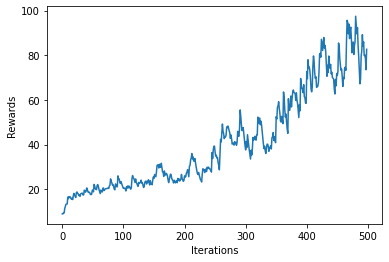

1/1 [==============================] - 0s 14ms/step


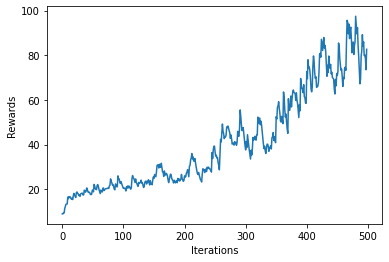

In [32]:
### Cartpole training! ###

# Learning rate and optimizer
learning_rate = 1e-3
optimizer = tf.keras.optimizers.Adam(learning_rate)

# instantiate cartpole agent
cartpole_model = create_cartpole_model()

# to track our progress
smoothed_reward = mdl.util.LossHistory(smoothing_factor=0.9)
plotter = mdl.util.PeriodicPlotter(sec=2, xlabel='Iterations', ylabel='Rewards')

if hasattr(tqdm, '_instances'): tqdm._instances.clear() # clear if it exists
for i_episode in range(500):

  plotter.plot(smoothed_reward.get())

  # Restart the environment
  observation = env.reset()
  memory.clear()

  while True:
      # using our observation, choose an action and take it in the environment
      action = choose_action(cartpole_model, observation)
      next_observation, reward, done, info = env.step(action)
      # add to memory
      memory.add_to_memory(observation, action, reward)
      
      # is the episode over? did you crash or do so well that you're done?
      if done:
          # determine total reward and keep a record of this
          total_reward = sum(memory.rewards)
          smoothed_reward.append(total_reward)
          
          # initiate training - remember we don't know anything about how the 
          # agent is doing until it has crashed!
          train_step(cartpole_model, optimizer,                                     
                     observations=np.vstack(memory.observations),
                     actions=np.array(memory.actions),
                     discounted_rewards = discount_rewards(memory.rewards))
          
          # reset the memory
          memory.clear()
          break
      # update our observatons
      observation = next_observation